# TPC のゲインマップ(Ba-133 の較正データ)

## ゲインマップと $K_a$, $K_b$

TPC のエネルギー(反跳電子のエネルギー `Ke`)は、アノードの FADC で測った **電荷 $Q$ [pC]** から求めます。
同じエネルギーを落としても、出てくる電荷は場所によって違います(µ-PIC・GEM のガス増幅率のむら、ASIC とエレキの増幅率の違い)。
そこで、検出面を区切った領域ごとに、電荷をエネルギーに直す 1 次式を決めておきます。

$$ E\,[\mathrm{keV}] = K_a\,Q\,[\mathrm{pC}] + K_b $$

| 量 | 単位 | 意味 |
|---|---|---|
| $K_a$ | keV/pC | 傾き。電荷 1 pC あたりのエネルギー。**ガス増幅率が高いほど小さい**(同じエネルギーで電荷が多く出る)。ガス増幅率 $G = (W/e) / K_a / 700$(9 節) |
| $K_b$ | keV | 切片。電荷が 0 のときのエネルギーで、理想的には 0。FADC の電荷は波形がベースライン + 閾値(20 ADU)を超えた部分しか積分しないので、小さい信号ほど電荷が少なめに出て、直線が原点から少しずれる分をここで吸収する |

**領域(組)**: アノードの FADC チャンネル 1 本は 1 つの ASIC = 32 ストリップ(25.6 mm)の電荷の和です。
アノード 12 本 × カソード 12 本の組で、検出面(30.72 cm 角)を 25.6 mm 角の 144 の領域に分け、組ごとに $K_a$, $K_b$ を決めます。
この 144 行の表が **ゲインマップ**(設定ファイルの `TPC_Calibration.ParameterFile`、例 `Calibration20190130.dat`)です。

```
 アノード ch  カソード ch  Ka [keV/pC]  Kb [keV]      (カソードの外側のループ、144 行)
```

**再構成での使われ方**(`TPC_Calibration`、`../1_DataIO/modules/3_TPC_Calibration/`): アノード ch $i$ の電荷 $Q_i$ を、
その ch とカソード ch $j$ のヒットの数で重みを付けて各組の式に通し、足し合わせます。

$$ K_e = \sum_i \sum_j \left( K_{a,ij}\,Q_i + K_{b,ij} \right) \frac{N_{ij}}{\sum_{j'} N_{ij'}} $$

$N_{ij}$ はアノード ch $i$ × カソード ch $j$ の領域のヒット(ストリップ × クロックの同時計数)の数で、100 を超える組だけ使います。
設定ファイルの `TPC_Calibration.Cal_Modify` は、全部の $K_a$, $K_b$ に掛ける係数です(Per02 では 1.453)。

## 作り方

TPC だけで測った Ba-133 のデータ(2017 年 12 月 19・20 日、11 run。20171219/Per01 は使わない)を使います。

| 手順 | 中身 | 節 |
|---|---|---|
| ① 1 ヒットのスペクトル | 電荷が正の FADC チャンネルがアノード・カソードとも 1 本だけのイベント(エネルギーがその組の領域だけに落ちた)で、そのアノード ch の電荷を組ごとに詰める | 4 |
| ② ピークの初期値 | Ba-133 の 30.85 keV(Ba の K X 線)と 8.04 keV(Cu の K X 線)のピークのおよその位置を `TSpectrum` で探す(Calamity と同じ探し方) | 5 |
| ③ ガウス関数のフィット | 各ピークに「ガウス関数 1 つ + 指数関数の背景」を当て、ピークの位置(平均)とその誤差を求める | 6 |
| ④ 較正 | 原点と 2 本のピークの 3 点に直線を当てて $K_a$, $K_b$ | 7 |
| ⑤ 確認と保存 | 全部の組のスペクトルとフィットを描いて確かめ、ゲインマップを書き出す | 8, 9 |

研究室のプログラム Calamity は ② で見つけたビンの位置をそのままピークの位置にします(ガウス関数は当てない)。
その方法で作ったものは `reference/GainMap_Calamity.ipynb` にあります(参照用)。

In [1]:
import sys, subprocess
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import ROOT
ROOT.gROOT.SetBatch(True)

# リポジトリの場所、チェーンの実行スクリプト、設定ファイル(config/*.json)の読み込み
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_script" / "run_chain.py").exists())
RUN_CHAIN = REPO / "run_script" / "run_chain.py"
sys.path.insert(0, str(REPO / "config"))
import ericanext_config as ec
CACHE = REPO / "tutorials_caldata" / "cache"   # チェーンの出力の置き場(チュートリアル間で共有)
CACHE.mkdir(exist_ok=True)

## 1. データの準備

Ba-133 の較正データ(`TPC_caldata/20171219`、`20171220`、合計約 190 GB)は、研究室の NAS の EricaNext_try のデータの置き場
(`/mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+`、`config/ericanext_config.py` の `DATA_DIR`)の `TPC_caldata/` にあります。
設定ファイルの `{tpc_caldata}` がこの場所になるので、NAS を読める計算機では何もしなくても動きます。

手元にコピーするときは、同じ並び(`<置き場>/TPC_caldata/20171219/Per08_TPC` など)でコピーし、環境変数 `SMILE2P_DATA` に `<置き場>` を設定します
(実データ・シミュレーションのデータも `<置き場>` から読むようになるので、`../1_DataIO/DataIO_example.ipynb` の 1 節の並びにそろえてください)。

設定ファイル `config/tpc_caldata_2017_Ba133.json` に、使う run の一覧(`runs`)、ピークのエネルギー(`peaks_keV`)、各モジュールのパラメータがあります。

In [2]:
CONFIG = "tpc_caldata_2017_Ba133"
cfg = ec.load(CONFIG)
print("tpc_caldata:", ec.tpc_caldata())
for run in cfg["runs"]:
    path = ec.tpc_caldata() / run
    print("OK     " if path.is_dir() else "MISSING", path)
PEAK_KEV = cfg["peaks_keV"]   # [30.85, 8.04]

tpc_caldata: /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/TPC_caldata
OK      /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/TPC_caldata/20171219/Per08_TPC
OK      /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/TPC_caldata/20171219/Per09_TPC
OK      /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/TPC_caldata/20171219/Per10_TPC
OK      /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/TPC_caldata/20171219/Per12_TPC
OK      /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/TPC_caldata/20171220/Per01_TPC
OK      /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/TPC_caldata/20171220/Per02_TPC
OK      /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/TPC_caldata/20171220/Per03_TPC
OK      /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/TPC_caldata/20171220/Per04_TPC
OK      /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/TPC_caldata/20171220/Per05_TPC
OK      /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/TPC_caldata/20171220/Per06_TPC
OK      /mnt/nas_eureka/onoda/EricaNext_try_da

## 2. 生データツリーを作る

run ごとに `ReadData → RawTreeWriter` を実行します。ターミナルでは、リポジトリの `run_script` ディレクトリで次を run ごとに実行するのと同じです(例は 20171219/Per08)。

```bash
cd EricaNext_try/run_script
python3 run_chain.py tpc_caldata_2017_Ba133 -o Ba133_20171219_Per08.root --raw --compression 505 \
    --set ReadData.data_dir=<TPC_caldata の場所>/20171219/Per08_TPC
```

| 引数 | 意味 |
|---|---|
| `tpc_caldata_2017_Ba133` | 設定ファイル。`ReadData.TPC_Only = true`(HA なし)、`RawTreeWriter` は波形の最大値がベースライン + 10 ADU 以下のチャンネルを保存しない・ヒットと HA は保存しない |
| `--set ReadData.data_dir=...` | run のディレクトリ(設定ファイルの値を上書き) |
| `--raw --compression 505` | 生データツリーだけを zstd で書く |

1 つの run に読み出していないボードの空のファイルがあっても、ReadData は自動で飛ばします。
**時間と大きさの目安:** 全 run で数時間、合計約 40 GB(大きい run は 20171220/Per06)。出力が既にある run は再実行しません。

In [3]:
RAWS = []
for run in cfg["runs"]:
    date, name = run.split("/")
    out = CACHE / f"Ba133_{date}_{name.replace('_TPC', '')}.root"
    cmd = [sys.executable, str(RUN_CHAIN), CONFIG, "-o", str(out), "--raw", "--compression", "505",
           "--set", f"ReadData.data_dir={ec.tpc_caldata() / run}"]
    if not out.exists():
        print(" ".join(cmd))
        r = subprocess.run(cmd, capture_output=True, text=True)
        if r.returncode != 0:
            print(r.stdout[-3000:], r.stderr[-3000:])
        r.check_returncode()
    RAWS.append(out)
print(len(RAWS), "runs")

11 runs


## 3. 設定

| 変数 | 意味 | 値 |
|---|---|---|
| `THRESHOLD` | 電荷を積分するサンプルの閾値 [ADU](CalcFADC の既定) | 20 |
| `REBIN` | ピーク探しのときにまとめるビンの数(Calamity の既定) | 40(2 pC × 40 = 80 pC) |
| `SEARCH` | ピークを探す電荷の範囲 [pC](Calamity の既定) | 250〜5000 |

In [4]:
THRESHOLD = 20.0
REBIN = 40
SEARCH = (250., 5000.)
MIN_EVENTS = 200          # これより 1 ヒットのイベントが少ない組は較正しない

## 4. 1 ヒットのスペクトル

下の C++ の関数で、波形から CalcFADC と同じ電荷 [pC] を計算し(`../1_DataIO/modules/2_CalcFADC/`)、1 ヒットのイベントを選びます。

- **チャンネルの番号:** 1 つの run に一部のボードしか無いとき、生データツリーの `fadc_ch` は「その run の何番目のボードか」で振られています。
  `run_info` のボード ID(1 始まり)を使って、物理的なチャンネル(アノード 0–11、カソード 12–23)に直します(`charges_phys`)。
- **1 ヒット:** 電荷が正のチャンネルが、アノード 12 本中 1 本、カソード 12 本中 1 本だけのイベント(SMILE_tool_box の CalcFADC の `SPEC_1Hit`)。
  詰めるのはアノードの電荷です(ゲインマップはアノードの電荷に掛けるため)。
- ヒストグラムは CalcFADC の `SPEC_1Hit` と同じ 5000 ビン(−100.5〜9899.5 pC、1 ビン 2 pC)。

全 run で数十分かかります。結果は `cache/Ba133_2017_spec1hit_thr20.root` に保存し、次からはそれを読みます。

In [5]:
ROOT.gInterpreter.Declare(r"""
// CalcFADC の電荷 [pC] を物理的なチャンネル(アノード 0-11、カソード 12-23)で返す
ROOT::RVecD charges_phys(const ROOT::RVec<short>& ch, const ROOT::RVec<short>& wave, double thr,
                         const ROOT::RVecI& amap, const ROOT::RVecI& cmap) {
  ROOT::RVecD q(24, -100. * 0.8);
  for (size_t i = 0; i < ch.size(); i++) {
    const short* w = &wave[i * 512];
    double mean = 0;
    for (int k = 0; k < 30; k++) mean += (double)w[k];
    mean /= 30;
    double c = 0; int n = 0;
    for (int k = 30; k < 500; k++)
      if ((double)w[k] - mean > thr) { c += (double)w[k] - mean; n++; }
    if (n == 0) c = -100;
    const int side = ch[i] / 12, idx = (ch[i] % 12) / 4, k4 = ch[i] % 4;
    const int board = side ? cmap[idx] : amap[idx];   // 0 始まりの物理的なボード
    q[12 * side + 4 * board + k4] = c * 2. * 20. / 50.;
  }
  return q;
}
// 1 ヒット: 電荷が正のチャンネルがアノード 1 本・カソード 1 本だけ -> {アノード ch, カソード ch, アノードの電荷}
ROOT::RVecD one_hit(const ROOT::RVecD& q) {
  int na = 0, nc = 0, ia = -1, ic = -1;
  for (int i = 0; i < 12; i++) {
    if (q[i] > 0) { na++; ia = i; }
    if (q[12 + i] > 0) { nc++; ic = i; }
  }
  if (na != 1 || nc != 1) return {-1., -1., 0.};
  return {double(ia), double(ic), q[ia]};
}
""")

SPEC_FILE = CACHE / f"Ba133_2017_spec1hit_thr{THRESHOLD:g}.root"
if not SPEC_FILE.exists():
    total = ROOT.TH2D("spec", "pair = 12 * anode + cathode;pair;anode charge [pC]", 144, -0.5, 143.5, 5000, -100.5, 9899.5)
    for i, f in enumerate(RAWS):
        info = ROOT.RDataFrame("RawTreeWriter/run_info", str(f)).AsNumpy(["anode_ids", "cathode_ids"])
        amap = ",".join(str(int(x) - 1) for x in info["anode_ids"][0])
        cmap = ",".join(str(int(x) - 1) for x in info["cathode_ids"][0])
        d = (ROOT.RDataFrame("RawTreeWriter/raw", str(f))
               .Define("q", f"charges_phys(fadc_ch, fadc_wave, {THRESHOLD}, ROOT::RVecI{{{amap}}}, ROOT::RVecI{{{cmap}}})")
               .Define("h", "one_hit(q)").Filter("h[0] >= 0")
               .Define("pair", "h[0] * 12 + h[1]").Define("qa", "h[2]"))
        h = d.Histo2D((f"spec{i}", "", 144, -0.5, 143.5, 5000, -100.5, 9899.5), "pair", "qa").GetValue()
        print(f.name, " boards: anode", amap, " cathode", cmap, " 1-hit events", int(h.GetEntries()))
        total.Add(h)
    fout = ROOT.TFile(str(SPEC_FILE), "recreate"); total.Write(); fout.Close()
spec_file = ROOT.TFile.Open(str(SPEC_FILE))
SPEC = spec_file.Get("spec")

def spectrum(a, c):
    """アノード ch a × カソード ch c の 1 ヒットのスペクトル(TH1D、2 pC / ビン)"""
    b = a * 12 + c + 1
    return SPEC.ProjectionY(f"SPEC_1Hit_A{a}_C{c}", b, b)

counts = np.array([[spectrum(a, c).GetEntries() for c in range(12)] for a in range(12)])
print("1-hit events:", int(counts.sum()))

1-hit events: 1920465


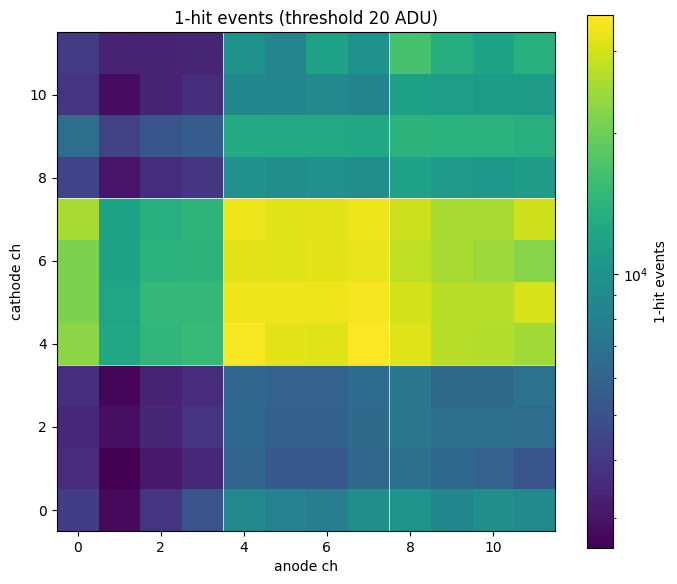

In [6]:
fig, ax = plt.subplots(figsize=(7, 6))
m = ax.imshow(counts.T, origin="lower", cmap="viridis", norm="log")
fig.colorbar(m, ax=ax, label="1-hit events")
ax.set_xlabel("anode ch"); ax.set_ylabel("cathode ch"); ax.set_title(f"1-hit events (threshold {THRESHOLD:g} ADU)")
for b in (3.5, 7.5):
    ax.axvline(b, color="w", lw=0.5); ax.axhline(b, color="w", lw=0.5)   # ボードの境目
fig.tight_layout()

## 5. ピークの初期値

フィットの初期値に使うピークのおよその位置を、Calamity の `Peak_Search1` と同じ手順で探します。

1. スペクトルを `REBIN` ビンずつまとめ(80 pC)、`SEARCH` の範囲の外を 0 にする
2. `TSpectrum::Search` でピークがちょうど 2 本見つかるまで、threshold と sigma を変えて探す
3. 電荷の大きい方を 30.85 keV、小さい方を 8.04 keV とする

4. 2 本の初期値の比 $Q_{30.85} / Q_{8.04}$ が 3.2〜4.6 の外なら(30.85 keV の山を取り違えた)、30.85 keV の初期値を
   8.04 keV の初期値 × 30.85 / 8.04 にする。8.04 keV のピークは鋭く、どの組でもほぼ正しく見つかる。直線がほぼ原点を通るなら、2 本の位置の比は 30.85 / 8.04 = 3.84 になる

それでも合わない組は、図を見て `MANUAL_PEAKS` に初期値を書きます(Calamity の「目分量」にあたる)。
ピークが読めない組は `[]` にすると較正しません。

In [7]:
def peak_search(h, n_peak):
    """Calamity Peak_Search1: n_peak 本のピークの位置 [pC] を大きい順に返す"""
    t = h.Clone(h.GetName() + "_search")
    t.Rebin(REBIN)
    for n in range(t.GetNbinsX()):
        if t.GetBinCenter(n) < SEARCH[0] or t.GetBinCenter(n) > SEARCH[1]:
            t.SetBinContent(n, 0.0)
    sp = ROOT.TSpectrum()
    sigma, thre, thre_n, found = 1., 0.5, 1., 0
    for _ in range(10):
        for _ in range(100):
            found = sp.Search(t, sigma, "nodraw goff", 1 - thre ** thre_n)
            if found == n_peak: break
            thre_n = thre_n * 2 if found > n_peak else thre_n / 3
        if found == n_peak: break
        sigma = sigma * 2 if found > n_peak else sigma / 3
    return sorted([sp.GetPositionX()[i] for i in range(found)], reverse=True)

peaks = {}
for a in range(12):
    for c in range(12):
        if counts[a, c] >= MIN_EVENTS:
            peaks[(a, c)] = peak_search(spectrum(a, c), len(PEAK_KEV))
n_ok = sum(1 for p in peaks.values() if len(p) == len(PEAK_KEV))
print(f"{len(peaks)} pairs with >= {MIN_EVENTS} events, {n_ok} with {len(PEAK_KEV)} peaks")

144 pairs with >= 200 events, 144 with 2 peaks


In [8]:
MANUAL_PEAKS = {
    # (アノード ch, カソード ch): [30.85 keV の初期値 [pC], 8.04 keV の初期値 [pC]]
    # 自動の探し方が別の山を拾った組(スペクトルを 20 pC のビンで見て決めた)
    (1, 1):  [1950., 580.],
    (1, 10): [1750., 540.],
    (2, 1):  [1930., 540.],
    (7, 0):  [1700., 430.],
    (7, 2):  [1550., 400.],
    (8, 0):  [1800., 430.],
    (1, 0):  [],               # 30.85 keV のピークが見えない -> 較正しない
}
def initial_peaks(key, h):
    """初期値: MANUAL_PEAKS、無ければ TSpectrum。2 本の比が 3.2〜4.6 の外なら 30.85 keV の初期値を 8.04 keV の初期値 × 30.85 / 8.04 にする"""
    if key in MANUAL_PEAKS:
        return MANUAL_PEAKS[key], False
    p = peak_search(h, len(PEAK_KEV))
    if len(p) == 2 and not 3.2 < p[0] / p[1] < 4.6:
        return [p[1] * PEAK_KEV[0] / PEAK_KEV[1], p[1]], True
    return p, False

seeds, replaced = {}, []
for a in range(12):
    for c in range(12):
        if counts[a, c] >= MIN_EVENTS:
            seeds[(a, c)], r = initial_peaks((a, c), spectrum(a, c))
            if r: replaced.append((a, c))
print(len(seeds), "pairs with >=", MIN_EVENTS, "events;", sum(len(p) == 2 for p in seeds.values()), "with 2 initial peaks")
print("30.85 keV の初期値を 8.04 keV から決めた組:", len(replaced), replaced)

144 pairs with >= 200 events; 143 with 2 initial peaks
30.85 keV の初期値を 8.04 keV から決めた組: 33 [(0, 2), (0, 5), (0, 7), (0, 8), (0, 9), (0, 10), (0, 11), (1, 2), (1, 4), (1, 11), (2, 2), (2, 9), (3, 3), (3, 9), (3, 11), (4, 0), (4, 10), (6, 2), (6, 11), (7, 3), (7, 9), (8, 10), (9, 0), (9, 1), (9, 8), (10, 4), (10, 5), (10, 8), (10, 10), (10, 11), (11, 0), (11, 6), (11, 11)]


## 6. ガウス関数のフィット

各ピークに、ガウス関数 1 つと、指数関数の背景(ピークは下がっていく連続成分の上に乗っている)を足した関数を当てます。

$$ f(Q) = A \exp\left(-\frac{(Q-\mu)^2}{2\sigma^2}\right) + \exp(c_0 + c_1 Q) $$

8.04 keV のピークは低いエネルギー側で形の変わる連続成分の上にあるので、範囲を狭く(0.75〜1.3 倍)、σ の上限を小さく(30 %)しています。
広げると、背景の指数関数が範囲の端で急に大きくなり、ピークと入れ替わることがあります。

30.85 keV の山は Ba の Kα 線(30.6, 31.0 keV)と Kβ 線(約 35 keV)が重なった広い山ですが、ガウス関数 1 つで当てます。
その平均 $\mu$ を 30.85 keV の位置とします(Calamity と同じ約束)。

| 変数 | 意味 | 値 |
|---|---|---|
| `FIT_REBIN` | フィットのときにまとめるビンの数 | 10(20 pC) |
| `FIT_WINDOW` | フィットの範囲(初期値の何倍から何倍まで) | 30.85 keV: 0.55〜1.6 倍、8.04 keV: 0.75〜1.3 倍 |
| `SIGMA0` | σ の初期値(初期値に対する割合) | 30.85 keV: 0.13、8.04 keV: 0.10 |
| `SIGMA_LIMIT` | σ の許す範囲(初期値に対する割合) | 30.85 keV: 0.05〜0.5、8.04 keV: 0.04〜0.3 |

当て方(5 つのパラメータを一度に動かすと、統計の少ない組で収束しなかったり、関数が範囲の端で暴走したりするため 2 段階にする):

1. $\mu$ と $\sigma$ を初期値に固定して、$A$ と背景だけを当てる
2. 範囲を制限して全部を当てる: $\mu$ は初期値の ±30 %、$\sigma$ は `SIGMA_LIMIT`、背景の傾き $c_1$ は範囲の中で背景が $e^{5}$ 倍より速く変わらない値

**ピークに当たったかの判定**(どれか 1 つでも外れたら、その組は較正しない):

| 条件 | 意味 |
|---|---|
| フィットの状態が 0 か 1 | 収束した(Minuit2 の 1 は誤差の行列を正定値に直したという注意で、値は使える) |
| χ²/自由度 が 3 より小さい | 関数がデータの形に合っている |
| ピークの有意度が 3 より大きい | ピークがある。$\mu \pm 2\sigma$ の範囲で「データ − 当てた背景」を足した数 $S$ を、その範囲のデータの数 $N$ の平方根で割った $S/\sqrt{N}$(ガウス関数の高さ $A$ の誤差は背景と強く相関して大きく出るので使わない) |
| $\mu$ と $\sigma$ が制限の端に張り付いていない | 別の場所に動こうとしていない |
| $\mu$ の誤差が $\mu$ の 10 % より小さい | 位置が決まっている |
| 2 本の位置の比 $\mu_{30.85} / \mu_{8.04}$ が 3.2〜4.6 | 直線がほぼ原点を通るなら 30.85 / 8.04 = 3.84 になる。別の山を拾った組を除く |

In [9]:
FIT_REBIN = 10
FIT_WINDOW = {0: (0.55, 1.6), 1: (0.75, 1.3)}    # 0: 30.85 keV, 1: 8.04 keV
SIGMA0 = {0: 0.13, 1: 0.10}
SIGMA_LIMIT = {0: (0.05, 0.5), 1: (0.04, 0.3)}
SIGNIF_MIN = 3.
CHI2NDF_MAX = 3.
ROOT.gErrorIgnoreLevel = ROOT.kFatal          # Minuit2 の注意の文を出さない
ROOT.Math.MinimizerOptions.SetDefaultMaxFunctionCalls(100000)   # 関数を呼ぶ回数の上限(既定より多く)

def fit_peak(h, seed, k, name):
    """ガウス関数 + 指数関数の背景 -> dict(status, signif, mu, mu_err, sigma, lo, hi, func, seed)"""
    t = h.Clone(name); t.Rebin(FIT_REBIN); t.SetDirectory(0)
    lo, hi = FIT_WINDOW[k][0] * seed, FIT_WINDOW[k][1] * seed
    fn = ROOT.TF1(name + "_f", "gaus(0) + expo(3)", lo, hi)
    ylo = max(t.GetBinContent(t.FindBin(lo)), 1.); yhi = max(t.GetBinContent(t.FindBin(hi)), 1.)
    c1 = np.log(yhi / ylo) / (hi - lo); c0 = np.log(ylo) - c1 * lo          # 背景の初期値: 範囲の両端を結ぶ指数関数
    amp = max(t.GetBinContent(t.FindBin(seed)) - np.exp(c0 + c1 * seed), 1.)
    fn.SetParameters(amp, seed, SIGMA0[k] * seed, c0, c1)
    fn.FixParameter(1, seed); fn.FixParameter(2, SIGMA0[k] * seed)               # 1) mu, sigma を固定
    t.Fit(fn, "QRN0B")
    fn.ReleaseParameter(1); fn.ReleaseParameter(2)                              # 2) 範囲を制限して全部
    fn.SetParLimits(0, 0., 1e9); fn.SetParLimits(1, 0.7 * seed, 1.3 * seed)
    fn.SetParLimits(2, SIGMA_LIMIT[k][0] * seed, SIGMA_LIMIT[k][1] * seed)
    fn.SetParLimits(4, -5. / (hi - lo), 3. / (hi - lo))                       # 背景が範囲の中で e^5 倍より速く変わらない
    status = int(t.Fit(fn, "QRN0B"))
    mu, sigma = fn.GetParameter(1), abs(fn.GetParameter(2))
    # ピークの有意度: mu ± 2 sigma で (データ - 背景) の和 / sqrt(データの和)
    S = N = 0.
    for i in range(1, t.GetNbinsX() + 1):
        x = t.GetBinCenter(i)
        if max(mu - 2 * sigma, lo) <= x <= min(mu + 2 * sigma, hi):
            S += t.GetBinContent(i) - np.exp(fn.GetParameter(3) + fn.GetParameter(4) * x); N += t.GetBinContent(i)
    chi2ndf = fn.GetChisquare() / fn.GetNDF() if fn.GetNDF() > 0 else np.inf
    return dict(status=status, signif=S / np.sqrt(N) if N > 0 else 0., mu=mu, mu_err=fn.GetParError(1), sigma=sigma,
                chi2ndf=chi2ndf, lo=lo, hi=hi, func=fn, seed=seed, k=k)

def check(r):
    """判定に外れた理由のリスト(空なら OK)"""
    why, s0 = [], r["seed"]
    if r["status"] not in (0, 1): why.append(f"status {r['status']}")
    if not r["chi2ndf"] < CHI2NDF_MAX: why.append(f"chi2/ndf {r['chi2ndf']:.1f}")
    if not r["signif"] > SIGNIF_MIN: why.append(f"no peak ({r['signif']:.1f})")
    if not abs(r["mu"] - s0) < 0.29 * s0: why.append("mu at limit")
    lim = SIGMA_LIMIT[r["k"]]
    if not 1.02 * lim[0] * s0 < r["sigma"] < 0.98 * lim[1] * s0: why.append("sigma at limit")
    if not r["mu_err"] < 0.1 * abs(r["mu"]): why.append("mu error")
    return why

fits, reasons = {}, {}
for key, p in seeds.items():
    if len(p) != len(PEAK_KEV):
        reasons[key] = ["no initial peaks"]; continue
    a, c = key
    r = [fit_peak(spectrum(a, c), p[k], k, f"fit_A{a}_C{c}_{k}") for k in range(2)]
    fits[key] = r
    why = [f"{PEAK_KEV[k]:g} keV: {w}" for k in range(2) for w in check(r[k])]
    ratio = r[0]["mu"] / r[1]["mu"] if r[1]["mu"] > 0 else np.nan
    if not 3.2 < ratio < 4.6: why.append(f"ratio {ratio:.2f}")
    if why: reasons[key] = why
good = sorted(k for k in fits if k not in reasons)
print(f"ピークに当たった組: {len(good)} / {len(seeds)}")
print(f"較正しない組: {len(reasons)}")
for k in sorted(reasons):
    print(f"  A{k[0]} C{k[1]}: {', '.join(reasons[k])}")

ピークに当たった組: 103 / 144
較正しない組: 41
  A0 C0: 30.85 keV: no peak (1.5), 30.85 keV: mu error, 8.04 keV: no peak (0.0), 8.04 keV: mu at limit, 8.04 keV: mu error, ratio 5.39
  A0 C1: 30.85 keV: no peak (0.9), 30.85 keV: mu error, 8.04 keV: status 3, 8.04 keV: sigma at limit, 8.04 keV: mu error
  A0 C2: 30.85 keV: status 2, 30.85 keV: sigma at limit, 8.04 keV: no peak (0.0), 8.04 keV: mu at limit, 8.04 keV: sigma at limit, 8.04 keV: mu error
  A0 C3: 30.85 keV: status 3, 30.85 keV: sigma at limit, 30.85 keV: mu error, 8.04 keV: status 3, 8.04 keV: chi2/ndf 3.2, 8.04 keV: sigma at limit, 8.04 keV: mu error
  A0 C4: 8.04 keV: no peak (-0.1), 8.04 keV: mu at limit, 8.04 keV: mu error, ratio 5.42
  A0 C5: 8.04 keV: no peak (0.0), 8.04 keV: mu at limit, 8.04 keV: sigma at limit, 8.04 keV: mu error, ratio 6.80
  A0 C6: 30.85 keV: sigma at limit
  A0 C7: 8.04 keV: mu at limit, 8.04 keV: mu error
  A0 C8: 8.04 keV: sigma at limit, ratio 5.86
  A0 C9: 30.85 keV: sigma at limit, 8.04 keV: no peak (0.0),

較正しない組の多くは、ピークの有意度が 3 に届かない(`no peak`)組です。端の ch(アノード 0 の列、カソード 0 と 11 の行など)で
1 ヒットのイベントが少なく、30.85 keV のピークがほとんど見えません(8 節の図)。

## 7. 較正($K_a$, $K_b$)

原点 (0, 0) と、2 本のピークの位置 $(\mu_{30.85}, 30.85)$, $(\mu_{8.04}, 8.04)$ の 3 点に直線 `pol1` を当てます(Calamity の `Calibration` と同じ式)。
点の重みは付けません(原点には誤差が決められないため)。ピークの位置の誤差は 8 節のマップで確かめます。

In [10]:
def calibrate(q_peaks):
    """原点 + ピークに pol1 -> (Ka [keV/pC], Kb [keV])"""
    x = np.array([0.] + list(q_peaks)); y = np.array([0.] + list(PEAK_KEV))
    g = ROOT.TGraph(len(x), x, y)
    f = ROOT.TF1("cal_pol1", "pol1", 0, 6000)
    f.SetParameters(0, 0.01)
    g.Fit(f, "Q", "", 0, 6000)
    return f.GetParameter(1), f.GetParameter(0)

cal = {k: calibrate([fits[k][0]["mu"], fits[k][1]["mu"]]) for k in good}
ka = np.array([v[0] for v in cal.values()]); kb = np.array([v[1] for v in cal.values()])
print(f"{len(cal)} pairs calibrated: Ka median {np.median(ka):.4f} keV/pC, Kb median {np.median(kb):.2f} keV")

103 pairs calibrated: Ka median 0.0193 keV/pC, Kb median -0.07 keV


## 8. 確認

全部の組のスペクトルとフィットです(横がアノード ch、縦がカソード ch で上が 11。Calamity のキャンバスと同じ並び)。
黒の線が当てた関数(ガウス関数 + 背景、フィットの範囲だけ)、点線がピークの位置 $\mu$ です。
タイトルは $K_a$ と、30.85 keV の分解能(FWHM = 2.35 σ / μ)です。
赤のタイトルは初期値を `MANUAL_PEAKS` で直した組、橙のタイトルは判定に外れて較正しない組です。

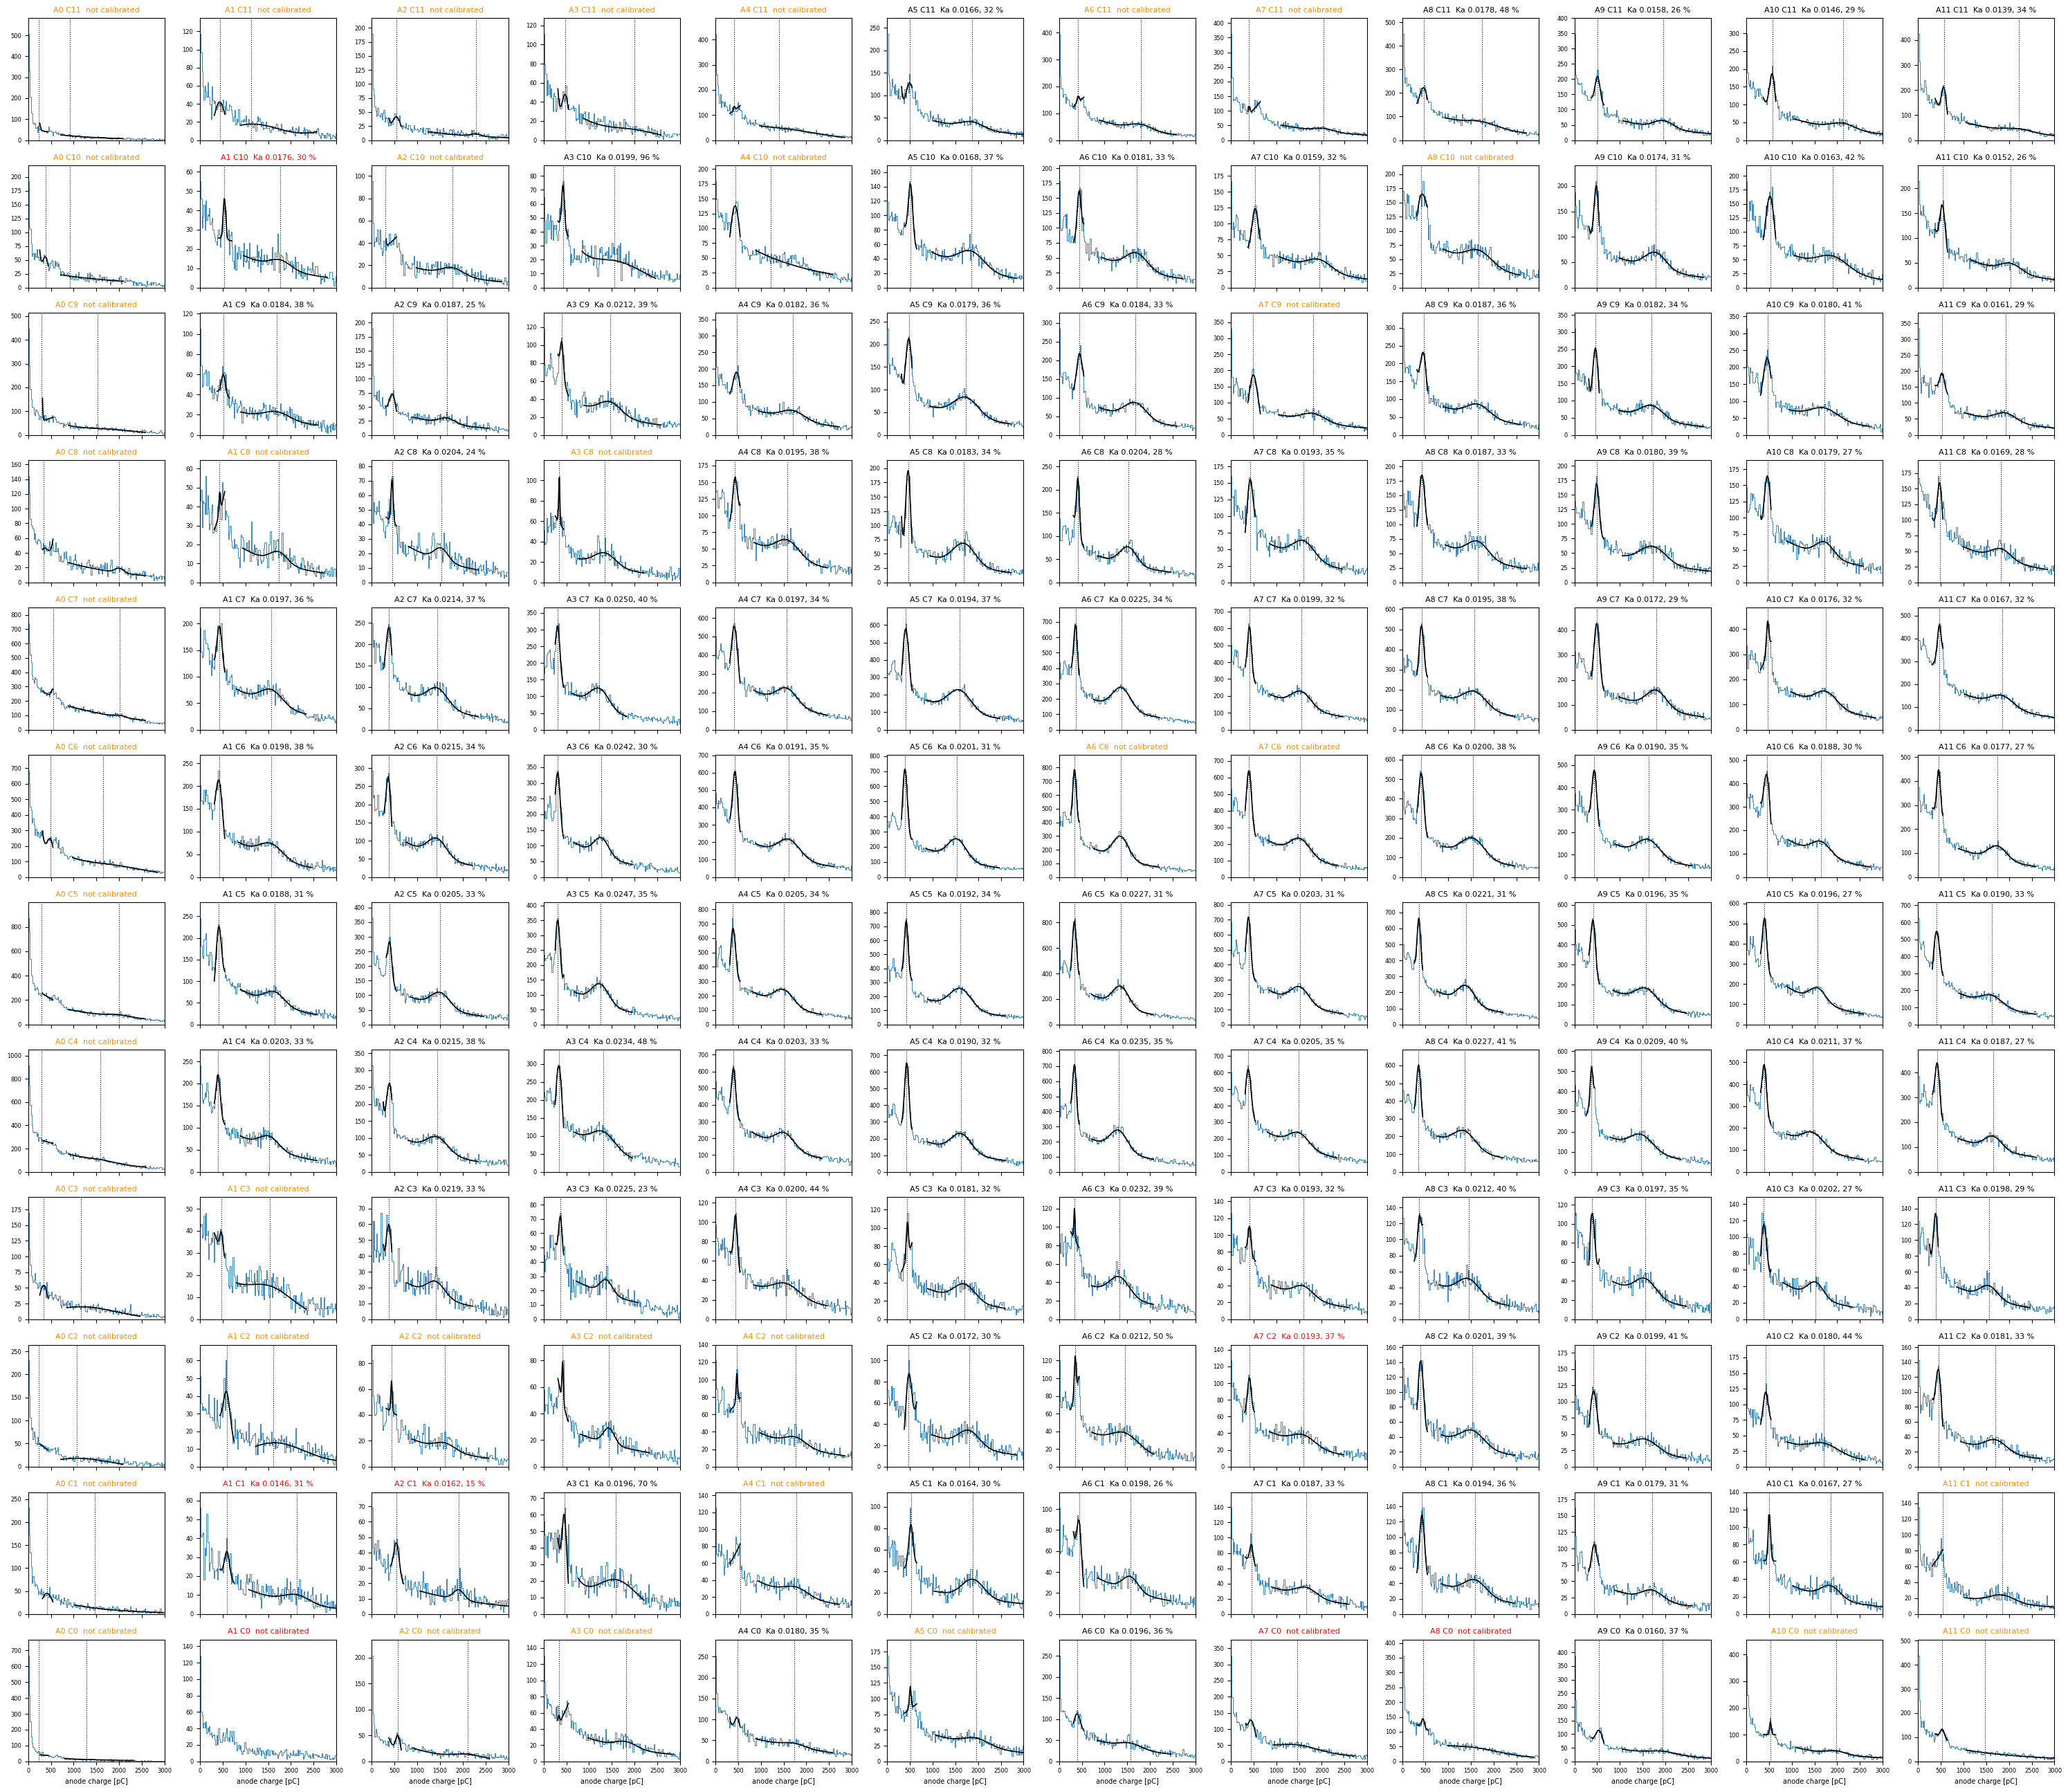

In [11]:
def pair_map(values, title, label, ax, fmt="{:.3g}", **kw):
    z = np.full((12, 12), np.nan)
    for (a, c), v in values.items():
        z[a, c] = v
    m = ax.imshow(z.T, origin="lower", cmap="viridis", **kw)
    plt.colorbar(m, ax=ax, label=label)
    for (a, c), v in values.items():
        ax.text(a, c, fmt.format(v), ha="center", va="center", fontsize=5, color="w")
    ax.set_xlabel("anode ch"); ax.set_ylabel("cathode ch"); ax.set_title(title)

fig, ax = plt.subplots(12, 12, figsize=(30, 26), sharex=True)
for a in range(12):
    for c in range(12):
        a_ = ax[11 - c, a]
        h = spectrum(a, c); h.Rebin(FIT_REBIN)
        x = np.array([h.GetBinCenter(i) for i in range(1, h.GetNbinsX() + 1)])
        y = np.array([h.GetBinContent(i) for i in range(1, h.GetNbinsX() + 1)])
        m = x < 3000
        a_.step(x[m], y[m], where="mid", lw=0.6)
        a_.set_ylim(0, 1.15 * y[m].max())
        for r in fits.get((a, c), []):
            xx = np.linspace(r["lo"], r["hi"], 150)
            a_.plot(xx, [r["func"].Eval(v) for v in xx], "k", lw=1.2)
            a_.axvline(r["mu"], color="k", ls=":", lw=0.8)
        if (a, c) in cal:
            r0 = fits[(a, c)][0]
            title, color = f"A{a} C{c}  Ka {cal[(a, c)][0]:.4f}, {r0['sigma'] / r0['mu'] * 235:.0f} %", "k"
        else:
            title, color = f"A{a} C{c}  not calibrated", "darkorange"
        if (a, c) in MANUAL_PEAKS:
            color = "r"
        a_.set_title(title, fontsize=8, color=color)
        a_.tick_params(labelsize=6); a_.set_xlim(0, 3000)
for a in range(12):
    ax[11, a].set_xlabel("anode charge [pC]", fontsize=7)
fig.tight_layout()

$K_a$, $K_b$、30.85 keV の分解能、30.85 keV のピークの位置の相対誤差のマップです。白い組は較正していません。

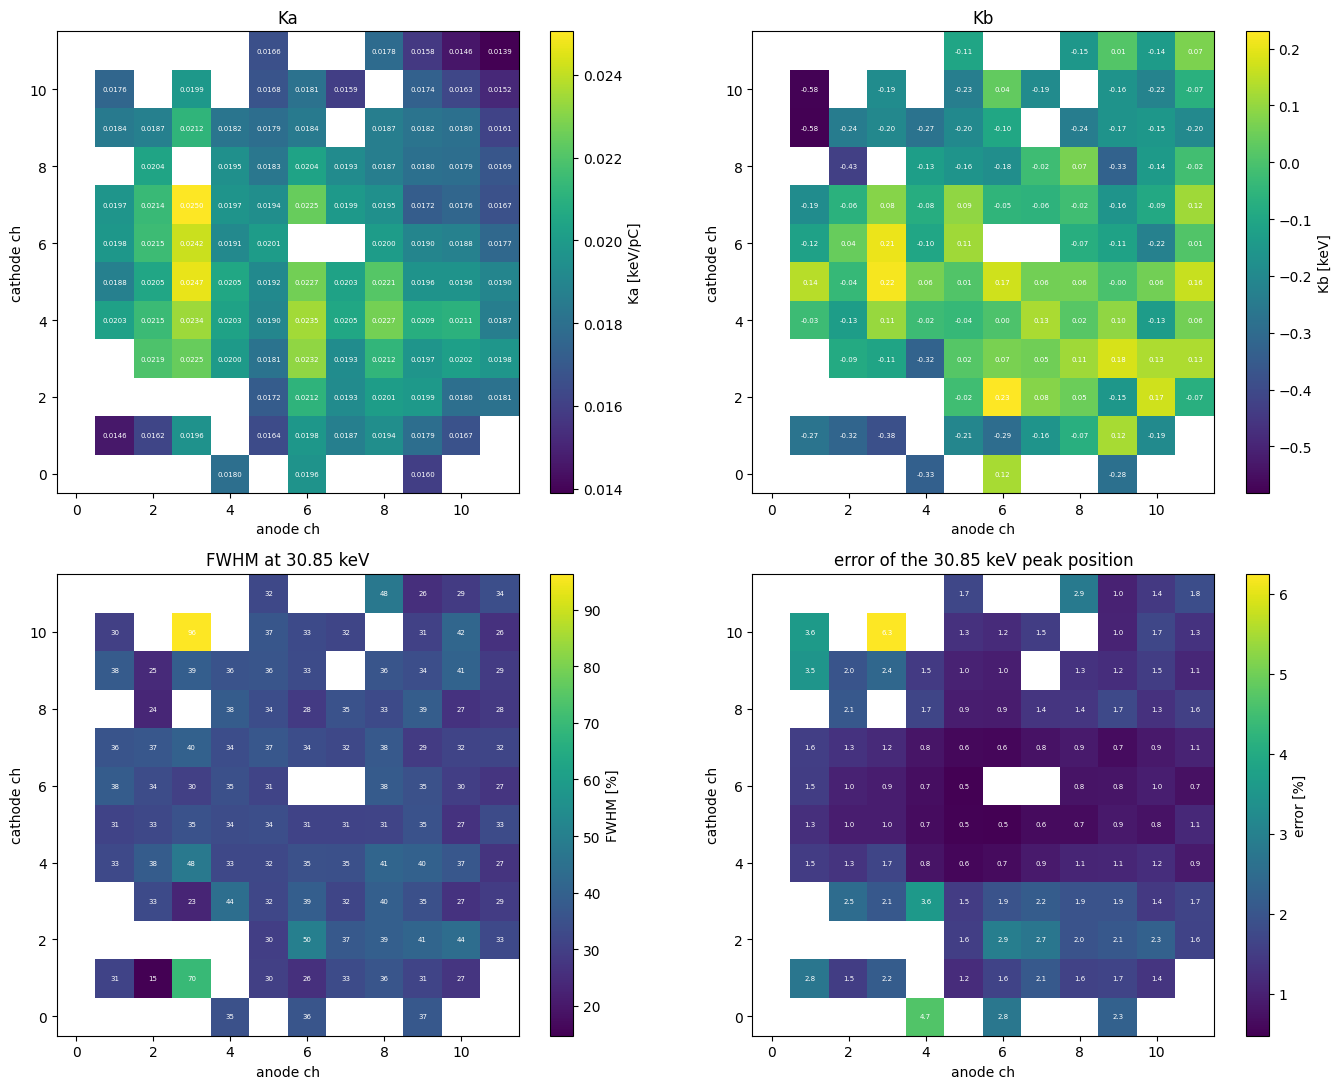

In [12]:
fig, ax = plt.subplots(2, 2, figsize=(14, 11))
pair_map({k: v[0] for k, v in cal.items()}, "Ka", "Ka [keV/pC]", ax[0, 0], "{:.4f}")
pair_map({k: v[1] for k, v in cal.items()}, "Kb", "Kb [keV]", ax[0, 1], "{:.2f}")
pair_map({k: fits[k][0]["sigma"] / fits[k][0]["mu"] * 235 for k in cal}, "FWHM at 30.85 keV", "FWHM [%]", ax[1, 0], "{:.0f}")
pair_map({k: fits[k][0]["mu_err"] / fits[k][0]["mu"] * 100 for k in cal}, "error of the 30.85 keV peak position", "error [%]", ax[1, 1], "{:.1f}")
fig.tight_layout()

## 9. ゲインマップを書き出す

TPC_Calibration が読む形(`アノード ch  カソード ch  Ka  Kb`、カソードの外側のループ)で書きます。

**較正しない組は $K_a = K_b = 0$ にします**(周りの組の値や別のゲインマップの値で埋めない)。
TPC_Calibration では、その組の領域の電荷がエネルギー `Ke` に入りません。端の ch(アノード 0 の列など)にエネルギーを落としたイベントは
`Ke` が小さく出るので、解析ではそれを承知で使うか、その領域を除いてください。
なお、当時のゲインマップ `TPC_caldata/Calibration20171219.dat`(20171219 の run だけから Calamity で作ったもの)は、144 組すべてに値が入っています。

作ったゲインマップを解析に使うときは、`run_chain.py` に `--set TPC_Calibration.ParameterFile=<パス>` を付けるか、設定ファイルの値を書き換えます。

In [13]:
OUT_CAL = CACHE / f"Calibration_Ba133_2017_thr{THRESHOLD:g}.dat"
with open(OUT_CAL, "w") as fout:
    for c in range(12):
        for a in range(12):
            ka_, kb_ = cal.get((a, c), (0., 0.))
            fout.write(f" {a}\t{c}\t{ka_:g}\t{kb_:g}\n")
print("wrote", OUT_CAL, f"({len(cal)} / 144 pairs calibrated)")

wrote /home/onoda/ANLNext/EricaNext_try/tutorials_caldata/cache/Calibration_Ba133_2017_thr20.dat (103 / 144 pairs calibrated)


## 10. ガス増幅率のマップ

Calamity の `Gain.c` と同じ式で、$K_a$ からガス増幅率を出します。1 keV あたりの電子の数は 1 / W(W = 23.6 eV)、
電子 1 個の電荷は 1.6 × 10⁻⁷ pC、700 はエレキの換算の係数(Calamity のまま)です。

$$ G = \frac{W / e}{K_a} \Big/ 700 = \frac{23.6\times10^{-3}\,\mathrm{keV} / 1.6\times10^{-7}\,\mathrm{pC}}{K_a} \Big/ 700 $$

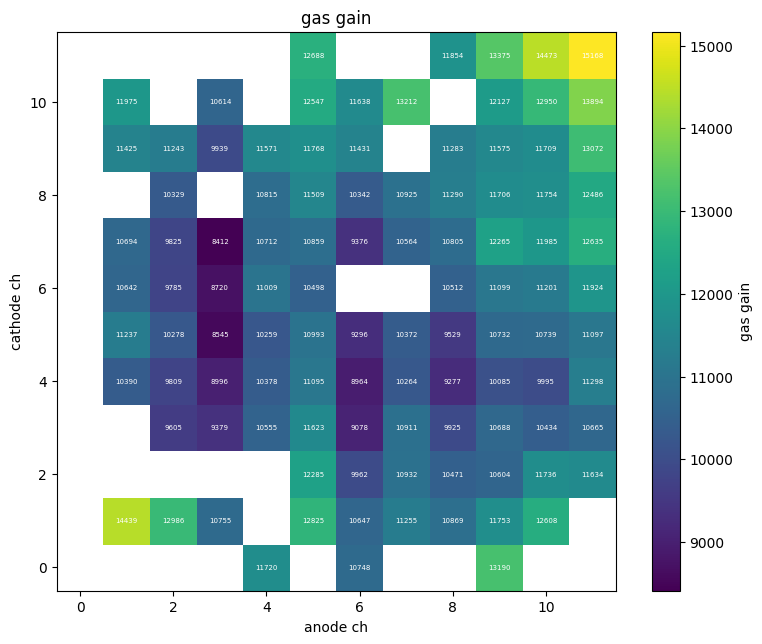

In [14]:
gain = {k: (23.6e-3 / 1.6e-7) / v[0] / 700 for k, v in cal.items() if v[0] > 0}
fig, ax = plt.subplots(figsize=(8, 6.5))
pair_map(gain, "gas gain", "gas gain", ax, "{:.0f}")
fig.tight_layout()